In [25]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
import operator

from langgraph.checkpoint.memory import InMemorySaver

In [26]:
load_dotenv()

True

In [27]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [28]:
class JokeState(TypedDict):
    
    topic : str
    joke : str
    explanation : str


In [29]:
def generate_joke(state : JokeState):
    prompt = f'generate a joke on the topic{state["topic"]}'
    response = model.invoke(prompt).content
    return {'joke':response}

In [30]:
def generate_explanation(state : JokeState):
    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = model.invoke(prompt).content
    return {'explanation' : response}

In [45]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer = checkpointer)

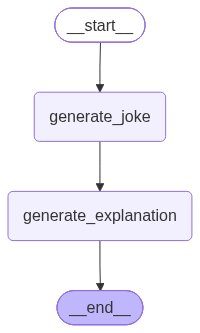

In [10]:
graph.compile()

In [46]:
config1 = {'configurable' : {'thread_id' : 1}}
workflow.invoke({'topic' : 'Pizza'}, config = config1)

{'topic': 'Pizza',
 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *slice* of the action! 🍕😄',
 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | How it’s used | Why it’s funny |\n|---------|---------------|----------------|\n| **Pizza** | A food item that’s usually just a thing you eat. | By giving it a human goal (“apply for a job”), the joke anthropomorphizes it, which is already a bit absurd and sets up the pun. |\n| **“Slice”** | 1. A piece of pizza.<br>2. A portion of something (e.g., “a slice of the action”). | The word is a double‑tune. The pizza’s “slice” can mean a literal piece of itself, but it also means “a share of the excitement.” |\n| **“Action”** | 1. The activity or excitement happening in a situation.<br>2. A film or scene that’s full of excitement. | In the phrase “slice of the action,” “action” is the activity people want to be part of. It’s also a common way to describe a movie’s exciting part. |\n| **The punchlin

In [34]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *crust* of a living! 🍕😄', 'explanation': '**Explanation of the joke**\n\n> **Why did the pizza apply for a job?  \n>  Because it wanted to get a *crust* of a living!**\n\nThis joke is a classic example of a *pun*—a play on words that relies on a double meaning.\n\n1. **The setup**  \n   The question frames a pizza as a human‑like character that can apply for a job, which is already a bit absurd and sets the stage for a light‑hearted punchline.\n\n2. **The punchline**  \n   The phrase “*crust* of a living” is a deliberate mis‑reading of the familiar idiom **“cost of living.”**  \n   - **Cost of living** is a common expression referring to the expenses required to maintain a standard of living.  \n   - In the joke, “crust” replaces “cost.” Because a pizza’s defining feature is its crust, the joke uses that word instead.\n\n3. **Why it’s funny**  \n   - **Wordplay**: The simil

In [35]:
# to get all the intermediate values 
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *crust* of a living! 🍕😄', 'explanation': '**Explanation of the joke**\n\n> **Why did the pizza apply for a job?  \n>  Because it wanted to get a *crust* of a living!**\n\nThis joke is a classic example of a *pun*—a play on words that relies on a double meaning.\n\n1. **The setup**  \n   The question frames a pizza as a human‑like character that can apply for a job, which is already a bit absurd and sets the stage for a light‑hearted punchline.\n\n2. **The punchline**  \n   The phrase “*crust* of a living” is a deliberate mis‑reading of the familiar idiom **“cost of living.”**  \n   - **Cost of living** is a common expression referring to the expenses required to maintain a standard of living.  \n   - In the joke, “crust” replaces “cost.” Because a pizza’s defining feature is its crust, the joke uses that word instead.\n\n3. **Why it’s funny**  \n   - **Wordplay**: The simi

In [36]:
config2 = {'configurable' : {'thread_id' : 2}}
workflow.invoke({'topic' : 'Indian politics'}, config = config2)

{'topic': 'Indian politics',
 'joke': 'Why did the Indian election campaign team bring a ladder to the polling station?  \nBecause they heard the vote counts were going to *climb* to new heights!',
 'explanation': '**Joke recap**\n\n> **Why did the Indian election campaign team bring a ladder to the polling station?  \n>  Because they heard the vote counts were going to *climb* to new heights!**\n\n---\n\n### What makes it funny?\n\n1. **Word‑play on “climb”**  \n   *Climb* has two common meanings:\n   * **Literal** – to ascend a ladder, stairs, or any vertical surface.  \n   * **Figurative** – to increase or rise (e.g., “sales are climbing”).\n   \n   The joke hinges on the double meaning. The campaign team interprets the phrase “vote counts are going to climb” literally and brings a ladder, as if they need a physical tool to reach higher numbers.\n\n2. **Exaggerated literalism**  \n   The absurdity comes from taking a metaphorical statement (vote counts rising) and treating it as a l

In [37]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'Indian politics', 'joke': 'Why did the Indian election campaign team bring a ladder to the polling station?  \nBecause they heard the vote counts were going to *climb* to new heights!', 'explanation': '**Joke recap**\n\n> **Why did the Indian election campaign team bring a ladder to the polling station?  \n>  Because they heard the vote counts were going to *climb* to new heights!**\n\n---\n\n### What makes it funny?\n\n1. **Word‑play on “climb”**  \n   *Climb* has two common meanings:\n   * **Literal** – to ascend a ladder, stairs, or any vertical surface.  \n   * **Figurative** – to increase or rise (e.g., “sales are climbing”).\n   \n   The joke hinges on the double meaning. The campaign team interprets the phrase “vote counts are going to climb” literally and brings a ladder, as if they need a physical tool to reach higher numbers.\n\n2. **Exaggerated literalism**  \n   The absurdity comes from taking a metaphorical statement (vote counts rising) and

In [23]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Indian politics', 'joke': 'Why did the Indian politician bring a ladder to Parliament?\n\nBecause he heard the debates were getting *high* and wanted to *climb* the political ladder!', 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | What it is | Why it’s funny |\n|---------|------------|----------------|\n| **The set‑up** | “Why did the Indian politician bring a ladder to Parliament?” | It’s a classic “why‑did‑he‑do‑that” question that signals a punchline that will involve a literal or absurd twist. |\n| **The word “high”** | In the punchline it’s used twice: “the debates were getting *high*” and “wanted to *climb* the political ladder.” | “High” can mean *elevated* or *lofty* (as in lofty rhetoric), but it also hints at *intoxication* (“high” from drugs). The joke plays on the *lofty* sense. |\n| **The phrase “political ladder”** | A common metaphor for career advancement in politics. | It’s a familiar saying, so the audience 

### Time Travel

In [48]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *slice* of the action! 🍕😄', 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | How it’s used | Why it’s funny |\n|---------|---------------|----------------|\n| **Pizza** | A food item that’s usually just a thing you eat. | By giving it a human goal (“apply for a job”), the joke anthropomorphizes it, which is already a bit absurd and sets up the pun. |\n| **“Slice”** | 1. A piece of pizza.<br>2. A portion of something (e.g., “a slice of the action”). | The word is a double‑tune. The pizza’s “slice” can mean a literal piece of itself, but it also means “a share of the excitement.” |\n| **“Action”** | 1. The activity or excitement happening in a situation.<br>2. A film or scene that’s full of excitement. | In the phrase “slice of the action,” “action” is the activity people want to be part of. It’s also a common way to describe a movie’s exciting part.

In [49]:
workflow.get_state({'configurable':{'thread_id':"1", "checkpoint_id":"1f1bf641-09e6-633a-8000-a3372f2e77a3"}})

StateSnapshot(values={'topic': 'Pizza'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1bf641-09e6-633a-8000-a3372f2e77a3'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-03T19:53:12.164639+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1bf641-0977-6ab4-bfff-c9a2f928ce2a'}}, tasks=(PregelTask(id='afafd0af-5622-bea1-fe9e-f5faacb8e512', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *slice* of the action! 🍕😄'}),), interrupts=())

In [50]:
workflow.invoke(None, {'configurable':{'thread_id':"1", "checkpoint_id":"1f1bf641-09e6-633a-8000-a3372f2e77a3"}})

{'topic': 'Pizza',
 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a slice of the action! 🍕😄',
 'explanation': '**Why the joke works**\n\nThe joke is a classic *word‑play* (or pun) that hinges on the double meaning of the phrase **“a slice of the action.”**  \n- **Literal meaning** – A pizza is literally made up of *slices*.  \n- **Figurative meaning** – “A slice of the action” is an idiom that means “a small part of something exciting or important.”\n\nSo the joke sets up an absurd scenario: a pizza is personified (it “applies for a job”) and says it wants *a slice of the action*. The humor comes from the unexpected overlap:\n\n1. **Personification** – The pizza is treated like a human who can apply for a job.  \n2. **Double entendre** – The phrase “a slice of the action” simultaneously refers to:\n   - A piece of pizza (the literal slice)  \n   - A piece of exciting work or a role in a busy workplace (the figurative slice of action)\n\nBecause the two meaning

In [51]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a slice of the action! 🍕😄', 'explanation': '**Why the joke works**\n\nThe joke is a classic *word‑play* (or pun) that hinges on the double meaning of the phrase **“a slice of the action.”**  \n- **Literal meaning** – A pizza is literally made up of *slices*.  \n- **Figurative meaning** – “A slice of the action” is an idiom that means “a small part of something exciting or important.”\n\nSo the joke sets up an absurd scenario: a pizza is personified (it “applies for a job”) and says it wants *a slice of the action*. The humor comes from the unexpected overlap:\n\n1. **Personification** – The pizza is treated like a human who can apply for a job.  \n2. **Double entendre** – The phrase “a slice of the action” simultaneously refers to:\n   - A piece of pizza (the literal slice)  \n   - A piece of exciting work or a role in a busy workplace (the figurative slice of action)\n\nBec

### Updating state

In [52]:
workflow.update_state({'configurable':{'thread_id':"1", "checkpoint_id":"1f1bf631-ac65-60ab-8000-e4e1b0b583cc",'checkpoint_ns': ''}},{'topic':'samosa'})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1bf643-76db-6421-8000-b60374620146'}}

In [53]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1bf643-76db-6421-8000-b60374620146'}}, metadata={'source': 'update', 'step': 0, 'parents': {}}, created_at='2026-10-03T19:54:17.276726+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1bf631-ac65-60ab-8000-e4e1b0b583cc'}}, tasks=(PregelTask(id='c16bfd69-4f3e-617a-926a-7ec108ad2267', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a slice of the action! 🍕😄', 'explanation': '**Why the joke works**\n\nThe joke is a classic *word‑play* (or pun) that hinges on the double meaning of the phrase **“a slice of the action.”**  \n- **Literal meaning** – A pizza is literally made up of *slices*.  \n- **F

In [54]:
workflow.invoke(None, {'configurable':{'thread_id':"1", "checkpoint_id":"1f1bf643-76db-6421-8000-b60374620146"}})

{'topic': 'samosa',
 'joke': 'Why did the samosa get a job at the bakery?\n\nBecause it wanted to *roll* in the dough and *crack* some jokes!',
 'explanation': '**Why the joke works**\n\n| Element | Explanation |\n|---------|-------------|\n| **The set‑up** – “Why did the samosa get a job at the bakery?” | A samosa is a deep‑fried, triangular pastry that you normally find in South‑Asian street food stalls, not a bakery. The very idea of a samosa “working” at a bakery is a surprise, which primes the listener for a punchline that will subvert expectations. |\n| **The punchline** – “Because it wanted to *roll* in the dough and *crack* some jokes!” | The humor comes from two layers of wordplay: |\n| 1. **“Roll in the dough”** |  *Literal:* Bakers roll dough to shape breads, pastries, etc.  *Figurative:* The idiom “roll in the dough” means to make a lot of money.  The samosa, a food item, wants to “roll” (as in handle dough) *and* “roll in the dough” (earn money). The double meaning makes t

In [55]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa get a job at the bakery?\n\nBecause it wanted to *roll* in the dough and *crack* some jokes!', 'explanation': '**Why the joke works**\n\n| Element | Explanation |\n|---------|-------------|\n| **The set‑up** – “Why did the samosa get a job at the bakery?” | A samosa is a deep‑fried, triangular pastry that you normally find in South‑Asian street food stalls, not a bakery. The very idea of a samosa “working” at a bakery is a surprise, which primes the listener for a punchline that will subvert expectations. |\n| **The punchline** – “Because it wanted to *roll* in the dough and *crack* some jokes!” | The humor comes from two layers of wordplay: |\n| 1. **“Roll in the dough”** |  *Literal:* Bakers roll dough to shape breads, pastries, etc.  *Figurative:* The idiom “roll in the dough” means to make a lot of money.  The samosa, a food item, wants to “roll” (as in handle dough) *and* “roll in the dough” (earn money). The do

### Fault Tolerance